# Neural network challenge

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

## Create challenge dataset
DO NOT CHANGE THE CODE THAT CREATES THE DATA SET

See how well you can get the neural network to perform on this data set

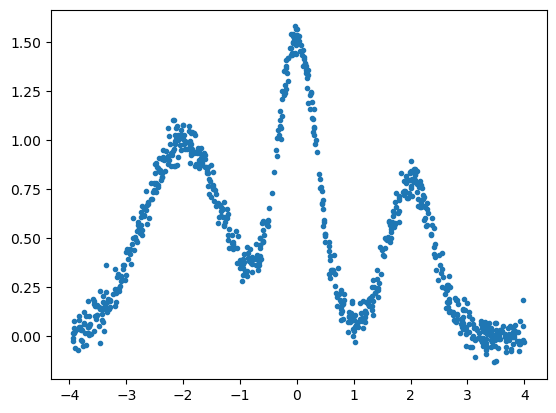

In [2]:
# Define weird function
def weird_fun(x):
    return (
        np.exp(-(x + 2)**2)
        + 1.5 * np.exp(-4 * x**2)
        + 0.8 * np.exp(-3 * (x - 2)**2)
    )

# Reset random seed
np.random.seed(1030)

# Set data parameters
N = 800 # Number of observations
s = 0.05 # Noise standard deviation
N_test = 200 # Number of test observations

# Create training set
x_train = np.sort(np.random.rand(N)*8-4)
y_train = weird_fun(x_train) + s*np.random.randn(N)

# Create test set
x_test = np.sort(np.random.rand(N_test)*8-4)
y_test = weird_fun(x_test) + s*np.random.randn(N_test)

# Plot training data
plt.plot(x_train, y_train, '.');

## Train a neural network

In [3]:
import torch
# H is hidden dimension
H = 5

# Device to use for computations
device = torch.device('cpu')
#device = torch.device('cuda')

# Create Tensors to hold inputs and outputs
x = torch.tensor(np.expand_dims(x_train,1), dtype=torch.float32, device=device)
y = torch.tensor(np.expand_dims(y_train,1), dtype=torch.float32, device=device)

# Manually set random seed
#torch.manual_seed(1)

dictionary = {}

kørsler = 100

# 1

for i in range(kørsler):

    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, 1),
    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device)
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device)
    y_t_pred = model(x_t)
    test_error = loss_fn(y_t_pred, y_t).item()


    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}
    # train_error_array.append(train_error)
    # test_error_array.append(test_error)

df1 = pd.DataFrame(data=dictionary)
df1 = df1.T

#print(train_error_array, test_error_array)
# plt.plot(Loss)
# plt.grid(True)

In [4]:
# 2
for i in range(kørsler):
    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, 1),
        torch.nn.ReLU(),


    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)

    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}

df2 = pd.DataFrame(data=dictionary)
df2 = df2.T

### Plot the fit and display error

In [5]:
# 3
for i in range(kørsler):
    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, 1),
    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)
    
    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}
df3 = pd.DataFrame(data=dictionary)
df3 = df3.T

In [6]:
# 4

for i in range(kørsler):
    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, 1),
        torch.nn.ReLU(),
    
    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)

    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}

df4 = pd.DataFrame(data=dictionary)
df4 = df4.T

In [7]:
# 5

for i in range(kørsler):

    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, 1),

    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)

    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}
df5 = pd.DataFrame(data=dictionary)
df5 = df5.T

In [8]:
# 6

for i in range(kørsler):
    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, 1),
        torch.nn.ReLU(),
    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)

    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}

df6 = pd.DataFrame(data=dictionary)
df6 = df6.T

In [9]:
# 7

for i in range(kørsler):
    # Use the nn package to define our model and loss function.
    model = torch.nn.Sequential(
        torch.nn.Linear(1, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),  # Another Linear layer otherwise fails
        torch.nn.ReLU(),
        torch.nn.Linear(H, 1)   # Output layer
    )
    model.to(device)
    loss_fn = torch.nn.MSELoss(reduction='mean')

    # Use the optim package to define an Optimizer that will update the weights of
    # the model for us. Here we will use Adam; the optim package contains many other
    # optimization algoriths. The first argument to the Adam constructor tells the
    # optimizer which Tensors it should update.
    learning_rate = 1e-3
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Number of iterations
    T = 5000
    # Allocate space for loss
    Loss = np.zeros(T)

    for t in range(T):
        # Forward pass: compute predicted y by passing x to the model.
        y_pred = model(x)

        # Compute and save loss.
        loss = loss_fn(y_pred, y)
        Loss[t] = loss.item()

        # Before the backward pass, use the optimizer object to zero all of the
        # gradients for the variables it will update (which are the learnable
        # weights of the model). This is because by default, gradients are
        # accumulated in buffers( i.e, not overwritten) whenever .backward()
        # is called. Checkout docs of torch.autograd.backward for more details.
        optimizer.zero_grad()

        # Backward pass: compute gradient of the loss with respect to model
        # parameters
        loss.backward()

        # Calling the step function on an Optimizer makes an update to its
        # parameters
        optimizer.step()

    # training data
    train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
    # train_error_array.append(train_error)

    # test data 
    x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
    y_t_pred = model(x_t) # move to forloop
    test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
    # test_error_array.append(test_error)

    # adding to dictionary
    dictionary[i] = {"train_error": train_error, "test_error": test_error}
df7 = pd.DataFrame(data=dictionary)
df7 = df7.T

In [10]:
# making a dataframe
df = pd.concat([
    df1.add_prefix("1_linear_"),
    df2.add_prefix("2_ReLU_"),
    df3.add_prefix("3_linear_"),
    df4.add_prefix("4_ReLU_"),
    df5.add_prefix("5_Linear_"),
    df6.add_prefix("6_ReLU_"),
    df7.add_prefix("7_linear_")

], axis=1)

# csv-file
df.to_csv(r'/Users/home/Documents/DTU/02461 Intelligent Systems/intelligente_systemer/LabReport4/rådata.csv', decimal=',', sep=';')

In [26]:
# statistics
n = len(df)
describe = df.describe()
z = stats.norm.ppf(1-.05/2) # 95% confidence interval
lower = df.mean() - z * (df.std() / np.sqrt(n))
upper = df.mean() + z * (df.std() / np.sqrt(n))
print(f"Confidens interval: [{lower}, {upper}]\n")

median = df.median()
p_lower = df.quantile(0.025, interpolation='lower')
p_upper = df.quantile(0.975, interpolation='higher')
# print(p_upper)

#print(describe)

Confidens interval: [1_linear_train_error    0.162089
1_linear_test_error     0.154125
2_ReLU_train_error      0.221345
2_ReLU_test_error       0.202596
3_linear_train_error    0.072389
3_linear_test_error     0.065359
4_ReLU_train_error      0.137992
4_ReLU_test_error       0.121428
5_Linear_train_error    0.040328
5_Linear_test_error     0.037145
6_ReLU_train_error      0.142282
6_ReLU_test_error       0.124769
7_linear_train_error    0.032688
7_linear_test_error     0.030005
dtype: float64, 1_linear_train_error    0.162089
1_linear_test_error     0.154125
2_ReLU_train_error      0.269084
2_ReLU_test_error       0.241646
3_linear_train_error    0.078445
3_linear_test_error     0.070610
4_ReLU_train_error      0.200338
4_ReLU_test_error       0.175297
5_Linear_train_error    0.050224
5_Linear_test_error     0.045946
6_ReLU_train_error      0.213482
6_ReLU_test_error       0.186404
7_linear_train_error    0.047231
7_linear_test_error     0.042767
dtype: float64]



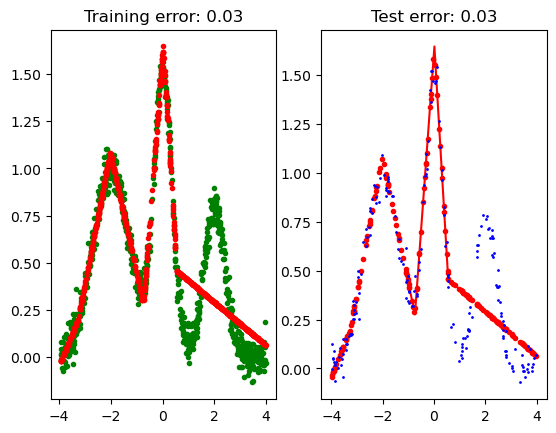

In [12]:
# Plot training data and fit
plt.subplot(121)
plt.plot(x_train, y_train, 'g.');
plt.plot(x_train, y_pred.cpu().detach().numpy(), 'r.')
train_error = loss_fn(y_pred, y).item() # calculate training error - move to forloop
plt.title('Training error: {:.2f}'.format(train_error))

# Plot test data and fit
x_t = torch.tensor(np.expand_dims(x_test,1), dtype=torch.float32, device=device) # move to forloop
y_t = torch.tensor(np.expand_dims(y_test,1), dtype=torch.float32, device=device) # move to forloop
y_t_pred = model(x_t) # move to forloop
x_all = np.linspace(-1,1,1000)
x_all_t = torch.tensor(np.expand_dims(x_all,1), dtype=torch.float32, device=device)
y_all_t = model(x_all_t)
plt.subplot(122)
plt.plot(x_all, y_all_t.cpu().detach().numpy(), 'r-');
plt.plot(x_test, y_t_pred.cpu().detach().numpy(), 'r.')
plt.plot(x_test, y_test, 'b.', markersize=2);
test_error = loss_fn(y_t_pred, y_t).item() # calculate test error - move to forloop 
plt.title('Test error: {:.2f}'.format(test_error));

## Exercise

$\star$ Experiment with 
- the number of hidden units
- the number of layers
- the type of non-linearity
- the number of iterations
- the learning rate

and see how low you can get the test error

$\star$ **Challenge**: Can you make the neural network so complex (by adding more hidden units/hidden layers) that it overfits to the training data? Can you bring the training error to zero?